# Ancestral reconstruction sharpness versus tree depth

How concentrated are marginal ancestral character distributions from root to tips? Compare available FT2 alphabets, amino acids and 3Di, using each strategy's **own alignment, fitted model and tree**. Sharpness is confidence, not accuracy against known ancestors.

Run in the `foldtree2` environment. This notebook only reads completed results; it never launches inference or modifies active queues. Rerun discovery to pick up newly completed families. Missing 10/50 results remain explicit.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/production_models.yaml').exists())
sys.path.insert(0, str(REPO))
from scripts.ancestral.ancestral_inspection import inventory, select_cohort, summarize_depth, bootstrap_curves, REPRESENTATIONS
RESULT_ROOTS = [REPO / 'runs/local_benchmarks/full_native_ancestral_20261001', REPO / 'runs/local_benchmarks/missing_alphabet_analysis_20261001']
COMMON_FAMILIES = True  # Intersection across representations with completed outputs.
MAX_FAMILIES = None     # All valid common families; set an integer for quick inspection.
DEPTH_BINS = 10
BOOTSTRAP_DRAWS = 1000
SEED = 42
MIN_FAMILIES_PER_BIN = 5
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = dict(zip(REPRESENTATIONS, plt.get_cmap('tab10').colors))

## Definitions

Depth = root-to-node branch distance / maximum root-to-tip distance in the family's own rooted tree. **0 is rootward; 1 is tipward.** This is normalized substitution distance, not time or matched nodes across strategies. Rooting uses recorded MAD/outgroup methods; inserted synthetic roots have no posterior and are omitted.

Maximum posterior probability (higher is sharper); normalized entropy H/log2(K) (lower is sharper); fraction with maximum probability >=0.90; uniform-baseline adjusted maximum (K*pmax-1)/(K-1). Normalization does not eliminate alphabet/model effects.

Keep occupancy-passing columns (at least four valid tips, <=30% missing). Average node/sites within family/depth bins, then weight families equally. Shading is a 95% **family bootstrap** interval, not an independent-site interval. Bins may have different contributing families; those below five are hidden by default. No cross-strategy node or column pairing.

In [2]:
cohort = json.loads((REPO / 'configs/oma_benchmark_cohort.json').read_text())
family_ids = {row['family'] for row in cohort['families']}
available, problems = inventory(RESULT_ROOTS, family_ids)
coverage = available.groupby('representation').family.nunique().reindex(REPRESENTATIONS, fill_value=0)
display(coverage.rename('completed_families').to_frame().assign(expected_families=len(family_ids)))
if not problems.empty:
    display(problems)
    raise ValueError('Resolve invalid/conflicting artifacts before interpretation.')
from ete3 import Tree
invalid_roots = []
for item in available.itertuples(index=False):
    directory = Path(item.directory)
    roots = directory / 'mad_input.nwk.rooted'
    if not roots.is_file():
        raise ValueError(f'Missing MAD root candidates: {directory}')
    count = sum(bool(line.strip()) for line in roots.read_text().splitlines())
    if count != 1:
        invalid_roots.append({'family': item.family, 'representation': item.representation,
                              'reason': f'{count} MAD roots'})
        continue
    tree = Tree(str(directory / 'rooted.nwk'), format=1)
    if len(tree.get_leaf_names()) != len(set(tree.get_leaf_names())):
        raise ValueError(f'Duplicate taxa in rooted tree: {directory}')
excluded_roots = pd.DataFrame(invalid_roots, columns=['family', 'representation', 'reason'])
if not excluded_roots.empty:
    display(excluded_roots)
    bad_pairs = set(zip(excluded_roots.family, excluded_roots.representation))
    available = available[[pair not in bad_pairs for pair in zip(available.family, available.representation)]]
selected = select_cohort(available, common=COMMON_FAMILIES, max_families=MAX_FAMILIES)
display(selected.groupby('representation').agg(families=('family', 'nunique'), nodes=('n_nodes', 'sum')))
print('Rooting:', selected.rooting.value_counts().to_dict())
print('Valid common families:', selected.family.nunique(), '/ 499; tied-root native runs excluded.')
print('Completion/provenance metadata checked; full output SHA256s are not recomputed during inspection.')

,completed_families,expected_families
representation,,
AA,499,499
3Di,499,499
FT2_10,499,499
FT2_20,499,499
FT2_30,499,499
FT2_40,499,499
FT2_50,0,499


,family,representation,reason
0,1029405,FT2_40,3 MAD roots
1,1058810,FT2_20,2 MAD roots
2,1058812,3Di,3 MAD roots
3,1067221,FT2_20,2 MAD roots
4,1067342,FT2_20,3 MAD roots
5,1067375,AA,2 MAD roots
6,1067442,AA,2 MAD roots
7,1312486,FT2_30,3 MAD roots
8,1332735,FT2_40,2 MAD roots
9,1335742,3Di,2 MAD roots


,families,nodes
representation,,
3Di,461,6020
AA,461,6020
FT2_10,461,6020
FT2_20,461,6020
FT2_30,461,6020
FT2_40,461,6020


Rooting: {'MAD_inferred': 2766}
Valid common families: 461 / 499; tied-root native runs excluded.
Completion/provenance metadata checked; full output SHA256s are not recomputed during inspection.


## Depth curves

Read gzip tables in chunks, retaining only family/bin summaries. The full 499-family analysis may take several minutes. Artifact pointers include inherited pilot results, avoiding duplicates. Change bins/family limit and rerun this section to refresh.

In [3]:
family_bins, eligibility = summarize_depth(selected, bins=DEPTH_BINS)
curves = bootstrap_curves(family_bins, draws=BOOTSTRAP_DRAWS, seed=SEED)
display(eligibility.groupby('representation')[['total_node_sites', 'eligible_node_sites']].sum())
display(curves.query("tip_entropy_group == 'all' and metric == 'max_probability'").pivot(index='depth_midpoint', columns='representation', values='n_families').fillna(0).astype(int))

,total_node_sites,eligible_node_sites
representation,,
3Di,3790235,2554318
AA,3853337,2621315
FT2_10,3795515,2629389
FT2_20,3849389,2629410
FT2_30,3873519,2615161
FT2_40,3789467,2643836


representation,3Di,AA,FT2_10,FT2_20,FT2_30,FT2_40
depth_midpoint,,,,,,
0.05,357,296,408,413,428,401
0.15,397,368,438,435,452,439
0.25,397,410,453,450,453,450
0.35,366,424,428,427,436,415
0.45,284,369,368,327,353,339
0.55,191,295,268,205,246,227
0.65,88,177,160,127,136,116
0.75,47,87,89,42,56,53
0.85,18,23,24,15,14,16


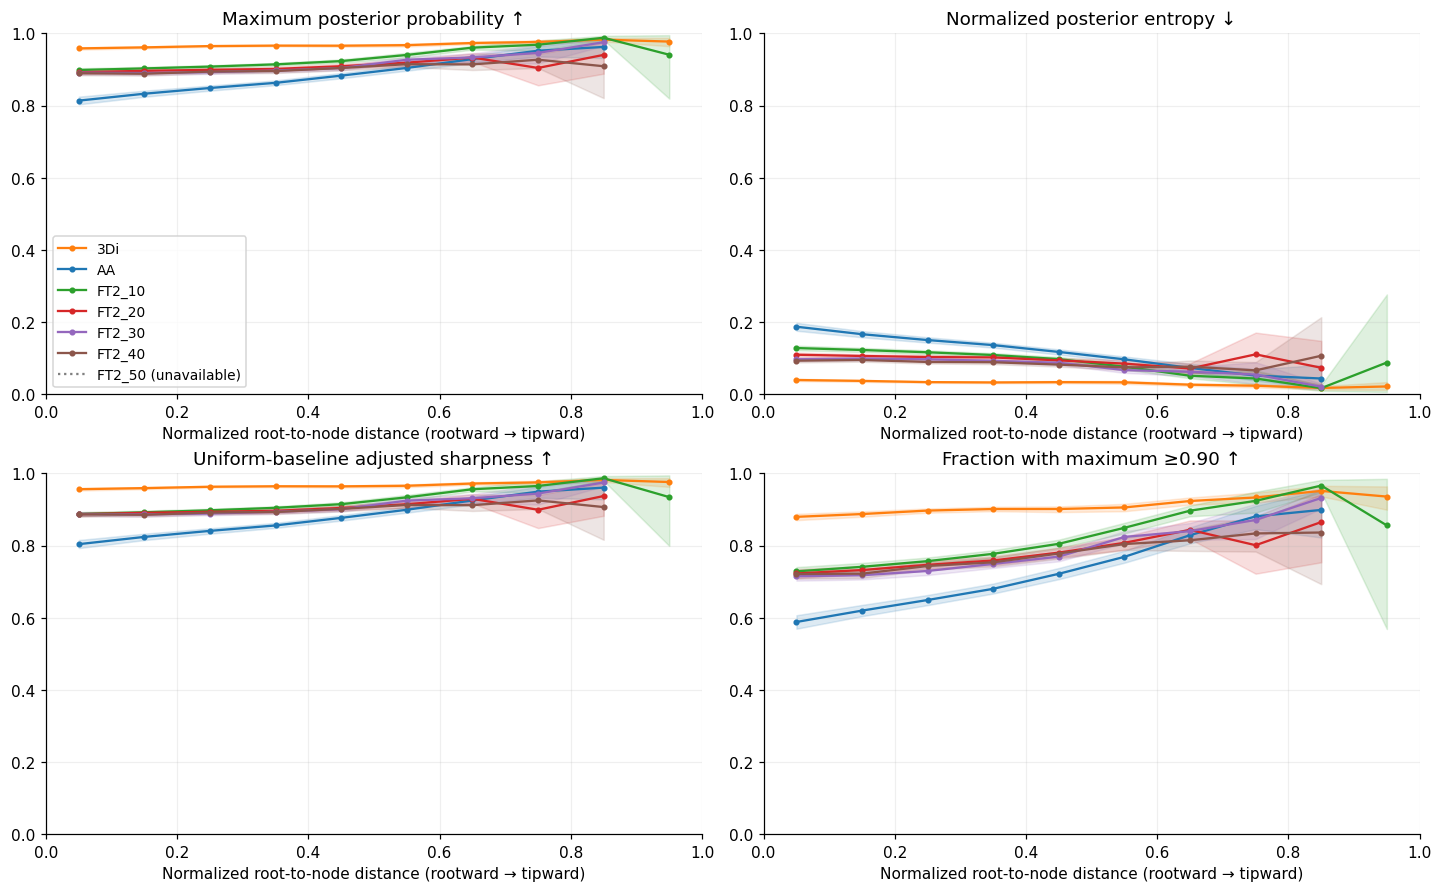

In [4]:
def plot_curve(ax, metric, entropy_group='all'):
    table = curves[(curves.metric == metric) & (curves.tip_entropy_group == entropy_group)]
    for name, group in table.groupby('representation'):
        group = group.sort_values('depth_bin')
        supported = group.n_families >= MIN_FAMILIES_PER_BIN
        x = group.depth_midpoint.to_numpy()
        ax.plot(x, group['mean'].where(supported).to_numpy(), marker='o', markersize=3, color=COLORS[name], label=name)
        ax.fill_between(x, group.lower.where(supported).to_numpy(), group.upper.where(supported).to_numpy(), color=COLORS[name], alpha=.15)
    for name in REPRESENTATIONS:
        if name not in set(table.representation):
            ax.plot([], [], color='gray', linestyle=':', label=name + ' (unavailable)')
    ax.set(xlabel='Normalized root-to-node distance (rootward → tipward)', ylim=(0, 1), xlim=(0, 1))
    ax.grid(alpha=.2)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, metric, title in zip(axes.flat, ['max_probability', 'normalized_entropy', 'sharpness', 'confidence_090'], ['Maximum posterior probability ↑', 'Normalized posterior entropy ↓', 'Uniform-baseline adjusted sharpness ↑', 'Fraction with maximum ≥0.90 ↑']):
    plot_curve(ax, metric)
    ax.set_title(title)
axes[0, 0].legend(fontsize=9)
plt.show()

## Conditioning on tip/column entropy

Split each strategy's own columns by normalized tip entropy: low <=1/3, medium <=2/3, high >2/3. These are strata, not paired homologous columns. Family coverage can be lower in each stratum.

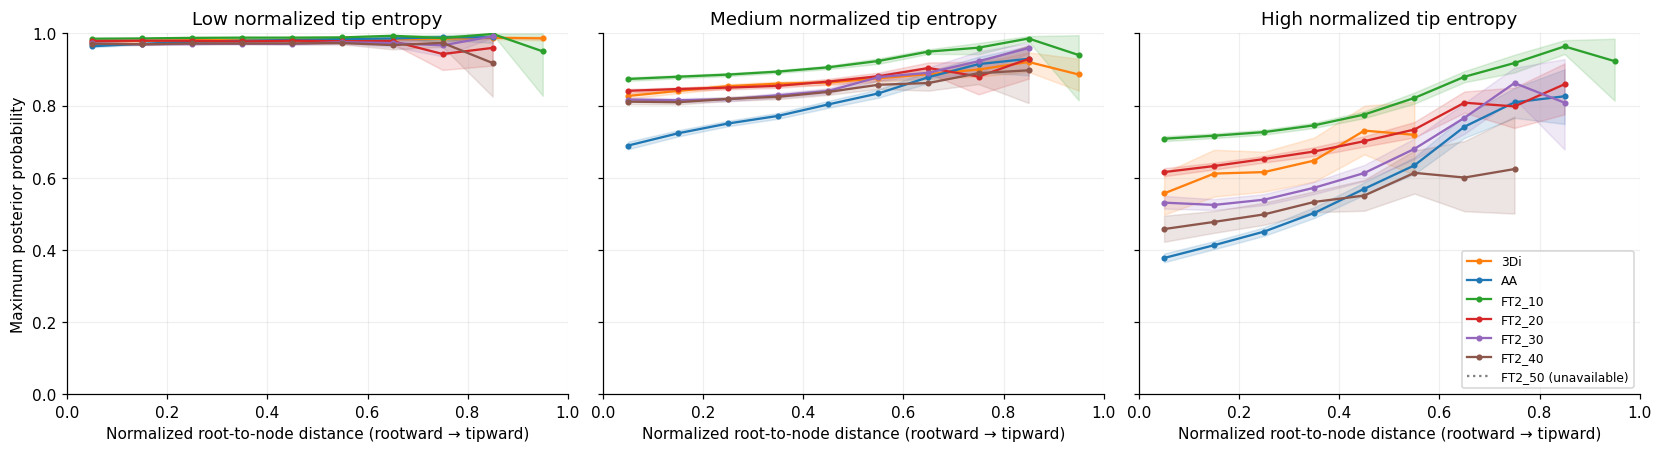

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
for ax, level in zip(axes, ['low', 'medium', 'high']):
    plot_curve(ax, 'max_probability', level)
    ax.set_title(f'{level.capitalize()} normalized tip entropy')
axes[0].set_ylabel('Maximum posterior probability')
axes[-1].legend(fontsize=8)
plt.show()

## Inspect one family across alphabets

The scatter shows mean maximum probability per node for each available native
alphabet. Heatmaps show up to twelve most uncertain eligible sites at the
rootward-most reconstructed node for each representation. Trees, node identities
and alignments differ, so nodes and site numbers are **not paired**. Missing
representations are labeled explicitly. FT2 characters are not decoded amino acids.


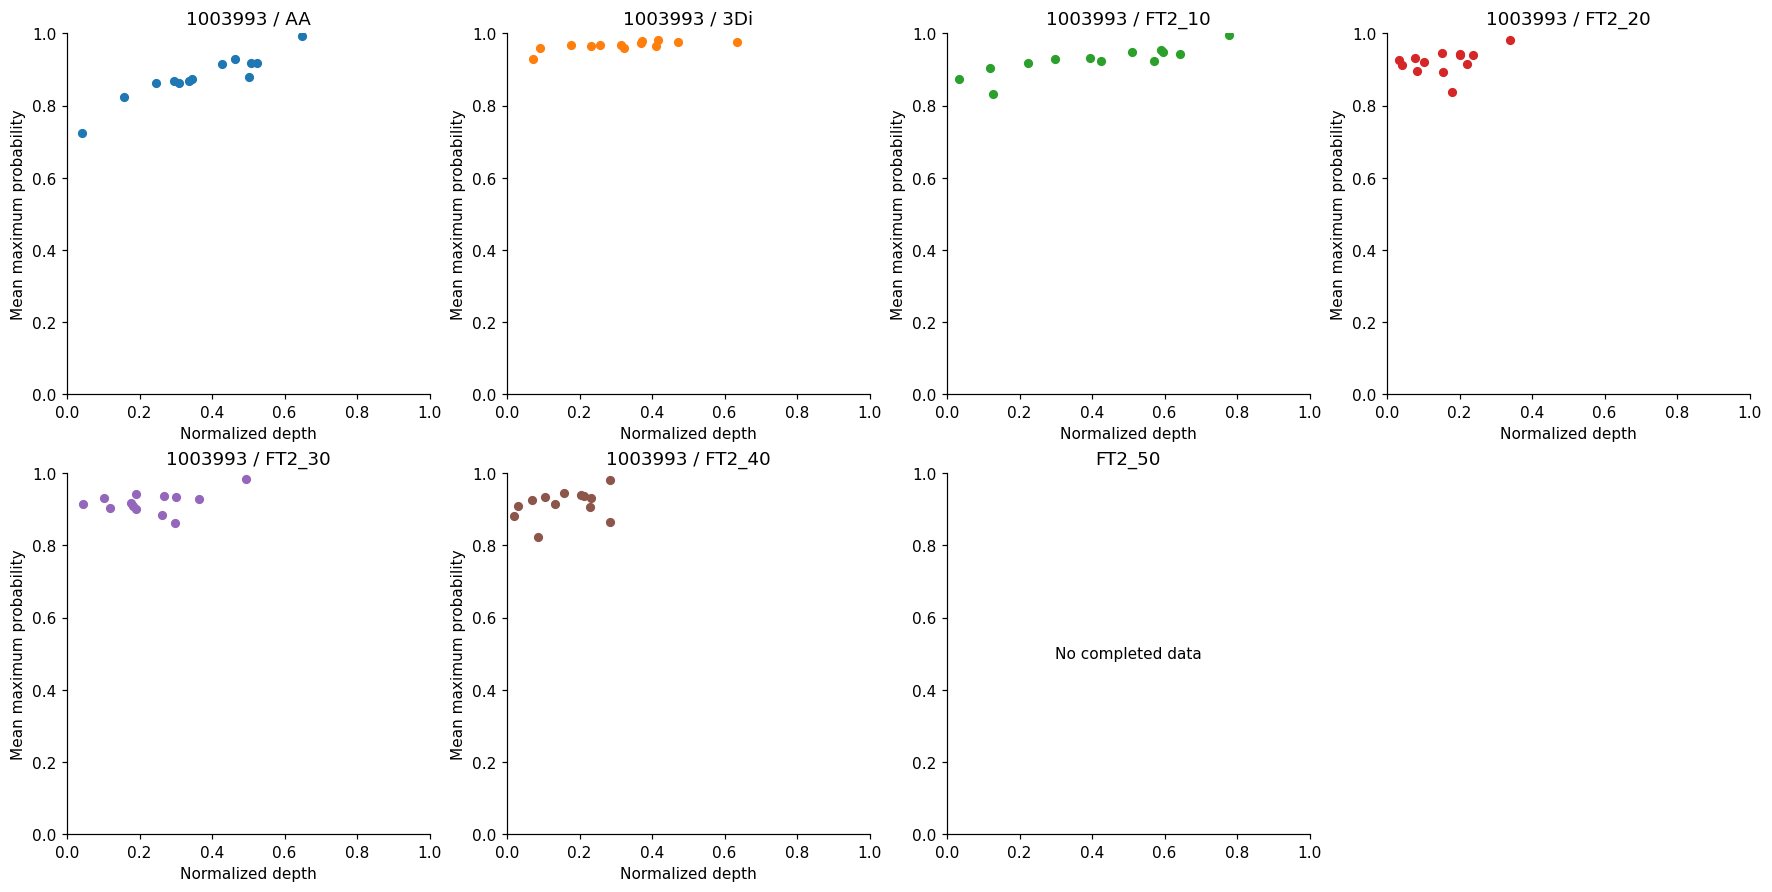

In [6]:
FAMILY = sorted(selected.family.unique())[0]  # Choose a family in the selected common cohort.
entries = selected[selected.family == FAMILY].set_index('representation')
details = {}
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
for ax, representation in zip(axes.flat, REPRESENTATIONS):
    if representation not in entries.index:
        ax.text(.5, .5, 'No completed data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(representation)
        continue
    entry = entries.loc[representation]
    detail = pd.read_csv(entry.table)
    detail = detail[detail.passes_occupancy == 1].copy()
    if detail.empty:
        raise ValueError(f'No occupancy-passing sites: {FAMILY}/{representation}')
    nodes = detail.groupby('node').agg(depth=('normalized_root_depth', 'first'),
        max_probability=('max_probability', 'mean'), descendant_tips=('descendant_tip_count', 'first'))
    details[representation] = (entry, detail, nodes)
    ax.scatter(nodes.depth, nodes.max_probability, color=COLORS[representation], s=25)
    ax.set(xlabel='Normalized depth', ylabel='Mean maximum probability',
           title=f'{FAMILY} / {representation}', xlim=(0, 1), ylim=(0, 1))
axes.flat[-1].set_visible(False)
plt.show()


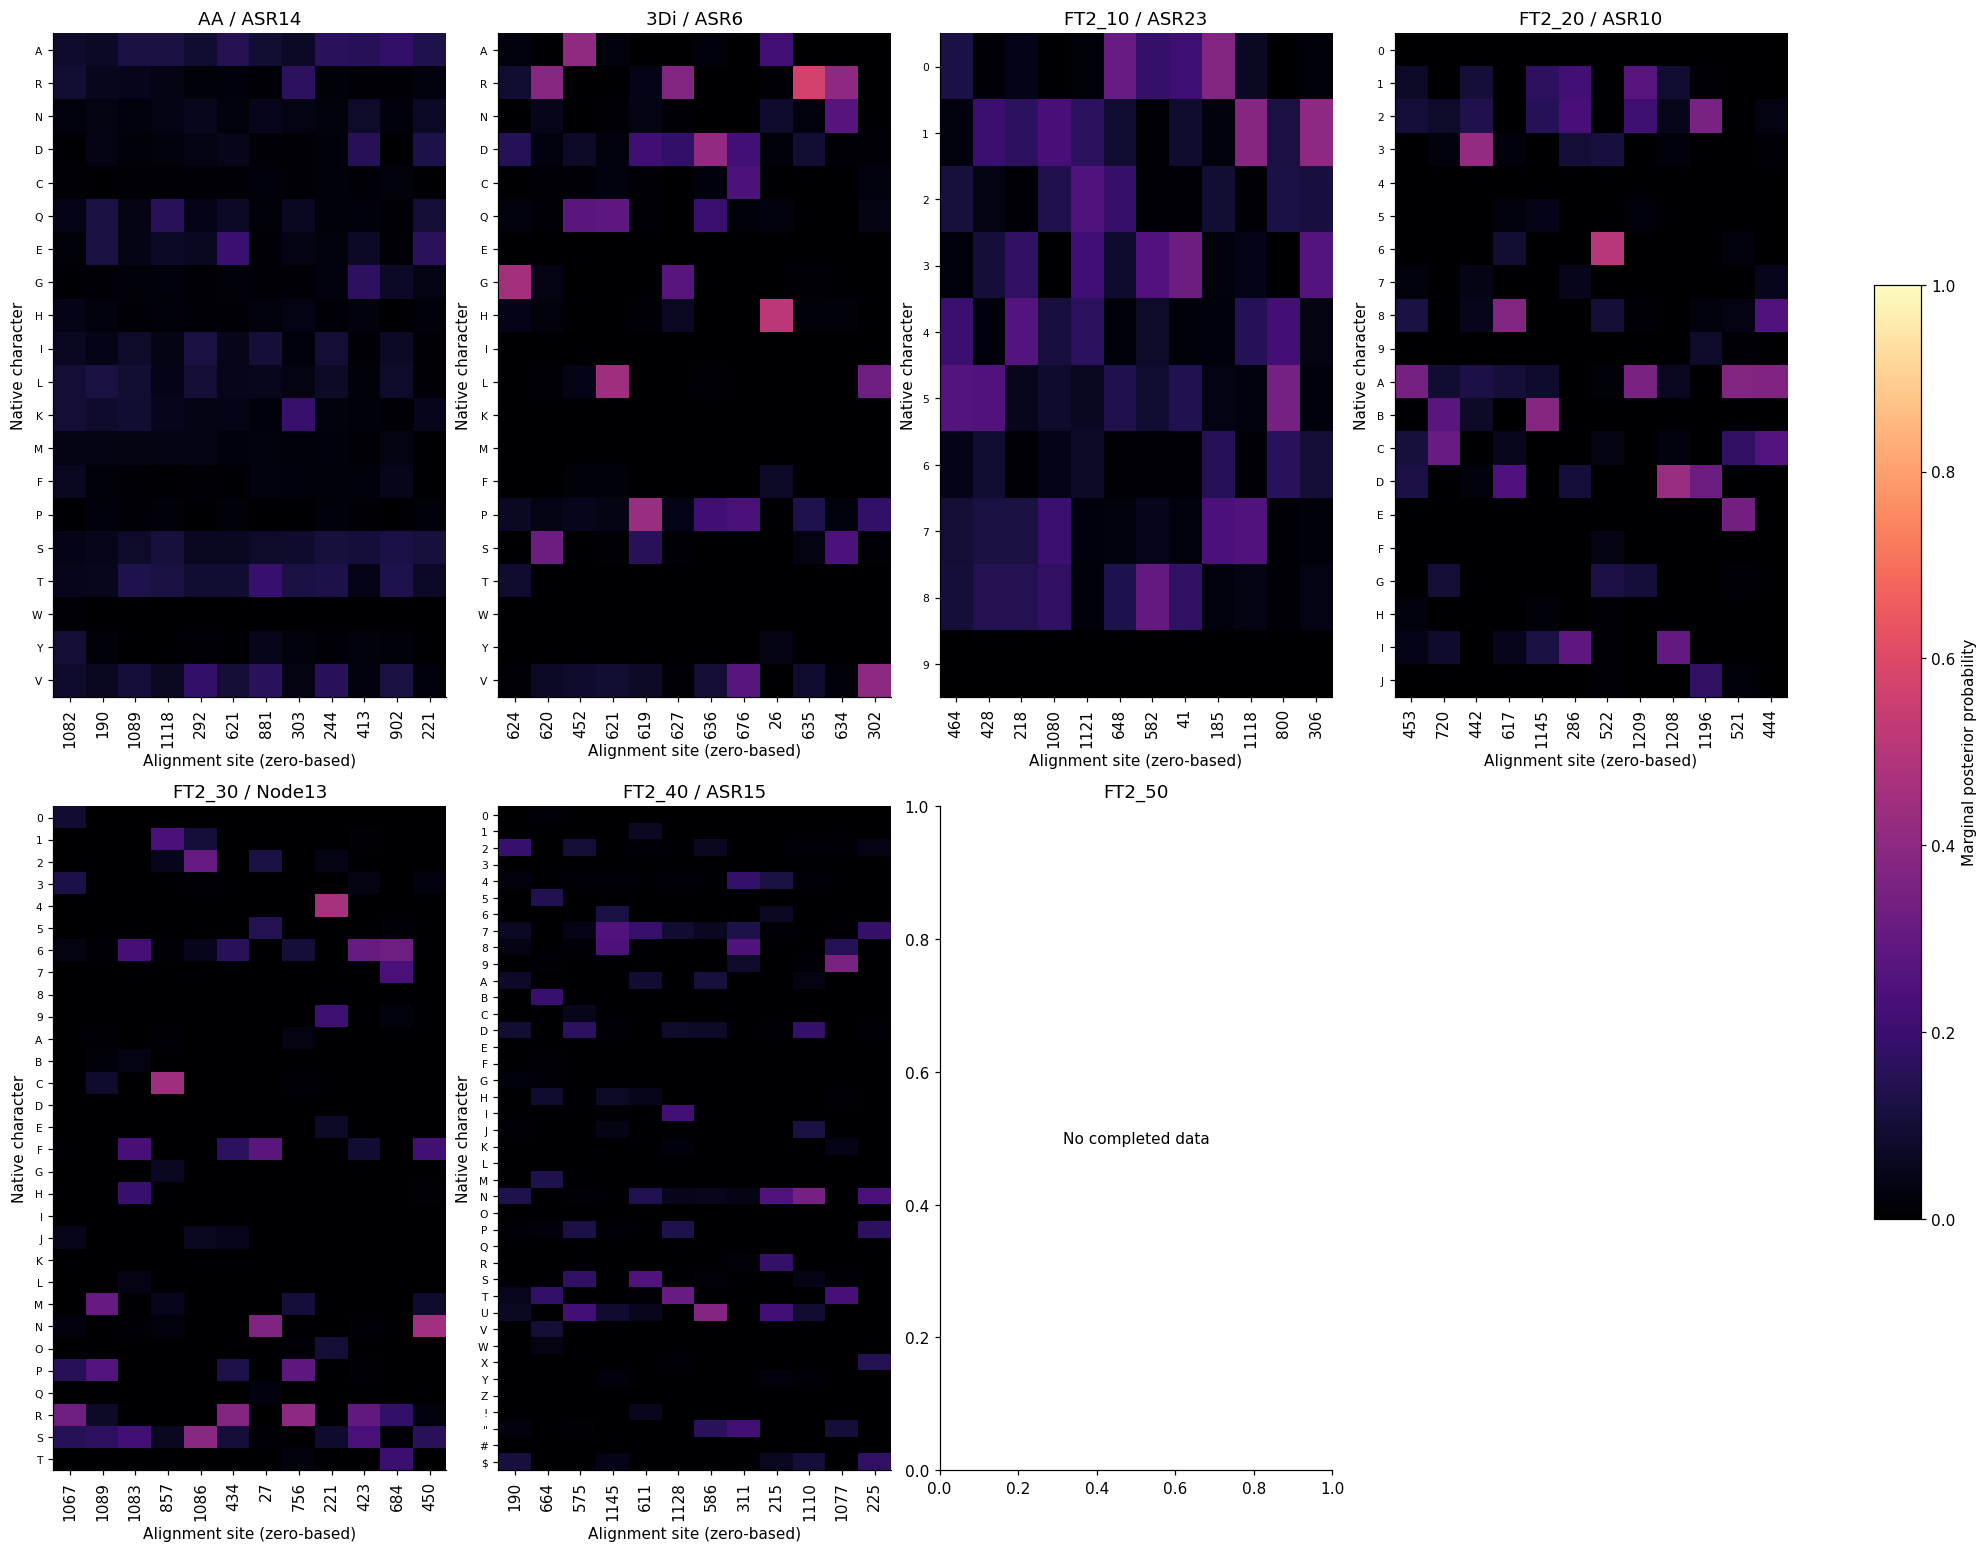

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 14), constrained_layout=True)
for ax, representation in zip(axes.flat, REPRESENTATIONS):
    if representation not in details:
        ax.text(.5, .5, 'No completed data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(representation)
        continue
    entry, detail, nodes = details[representation]
    node = nodes.sort_values('depth').index[0]
    sites = detail[detail.node == node].sort_values('normalized_entropy', ascending=False).head(12)
    state_order = json.loads((Path(entry.directory) / 'summary.json').read_text())['state_order']
    im = ax.imshow(sites[['p_' + state for state in state_order]].to_numpy().T,
                   aspect='auto', vmin=0, vmax=1, cmap='magma')
    ax.set_xticks(range(len(sites)), labels=sites.site.astype(str), rotation=90)
    ax.set_yticks(range(len(state_order)), labels=state_order)
    ax.tick_params(axis='y', labelsize=7)
    ax.set(xlabel='Alignment site (zero-based)', ylabel='Native character',
           title=f'{representation} / {node}')
fig.colorbar(im, ax=list(axes.flat[:-1]), label='Marginal posterior probability', shrink=.65)
axes.flat[-1].set_visible(False)
plt.show()


## Interpretation checklist

Sharpness is confidence, not ancestral accuracy. Alphabet size, fitted rates,
rooting, composition and alignment differences affect comparisons. The native
curves use valid families common across available representations; tied-root
legacy runs are excluded. FT2-50 has no completed native results. The paired
ARPIP section below does not include FT2-10 or FT2-50 because those runs have
not been completed. Normalized depth is not evolutionary time.


## Paired ARPIP versus RAxML

This separate analysis reads the completed indel benchmark, not the native-ASR
subset above. For each completed paired alphabet it uses all frozen families and the same
alignment, tree and shared nodes for the three methods. At ARPIP-present
node/sites, it averages conditional substitution entropy within each family,
divides by log₂(alphabet size), then weights families equally. Lower normalized
entropy means sharper distributions. The fitted RAxML model may include +I;
the constant-rate RAxML control removes it. AA and 3Di fitted models also
include gamma rate variation, which the constant-rate control removes.

ARPIP conditions on one inferred insertion point and presence mask. Its gap
fraction is a deterministic reconstruction, **not** a posterior probability of
absence. The plots exclude gaps from all three entropy calculations and show
the gap fraction separately. Neither sharpness nor agreement measures accuracy.
The benchmark uses fixed, experimental indel rates and no occupancy filter.


In [8]:
from scripts.benchmark_common import digest
from scripts.benchmarks.benchmark_cohort import verify_stage

INDEL_ROOT = REPO / 'runs/local_benchmarks/indel_asr_full_conditional_20261108'
indel_signature = verify_stage(INDEL_ROOT)
if digest(REPO / 'configs/oma_benchmark_cohort.json') != indel_signature['cohort_sha256']:
    raise ValueError('Frozen cohort does not match the indel benchmark')
indel_summary = json.loads((INDEL_ROOT / 'summary.json').read_text())
if indel_summary['status'] != 'completed':
    raise ValueError('Indel benchmark is incomplete')
indel = pd.DataFrame(indel_summary['results'])
expected_families = set(indel_signature['families'])
expected_sizes = {f'FT2_{size}' for size in indel_signature['sizes']}
expected_pairs = {(family, size) for family in expected_families for size in expected_sizes}
actual_pairs = set(zip(indel.family, indel.representation))
if (len(indel) != len(expected_pairs) or actual_pairs != expected_pairs
        or expected_families != family_ids or expected_sizes != {'FT2_20', 'FT2_30', 'FT2_40'}):
    raise ValueError('Indel results do not cover the complete frozen cohort and three alphabets')
if ((indel.present_sites <= 0).any()
        or (indel.n_node_sites != indel.present_sites + indel.arpip_gap_sites).any()):
    raise ValueError('Invalid ARPIP presence/gap counts')

indel['alphabet_size'] = indel.representation.str.removeprefix('FT2_').astype(int)
methods = {'ARPIP': 'arpip', 'RAxML fitted': 'raxml', 'RAxML constant': 'raxml_constant'}
for label, column in methods.items():
    indel[label] = indel[f'mean_entropy_{column}_present'] / np.log2(indel.alphabet_size)
if not np.isfinite(indel[list(methods) + ['arpip_gap_fraction']].to_numpy()).all():
    raise ValueError('Nonfinite benchmark entropy or gap values')
if not indel[list(methods) + ['arpip_gap_fraction']].apply(lambda col: col.between(0, 1)).all().all():
    raise ValueError('Benchmark entropy or gap values outside [0, 1]')
display(indel.groupby('representation').agg(
    families=('family', 'nunique'), shared_node_sites=('n_node_sites', 'sum'),
    present_node_sites=('present_sites', 'sum'), mean_gap_fraction=('arpip_gap_fraction', 'mean'),
    **{label: (label, 'mean') for label in methods}).round(4))


,families,shared_node_sites,present_node_sites,mean_gap_fraction,ARPIP,RAxML fitted,RAxML constant
representation,,,,,,,
FT2_20,499,4110869,3103027,0.2163,0.1169,0.1202,0.1169
FT2_30,499,4137244,3122056,0.2171,0.1103,0.1141,0.1102
FT2_40,499,4049047,3086759,0.2099,0.1031,0.1050,0.1031


### Native RAxML baselines for AA, 3Di and FT2-10

These separate AA, 3Di and FT2-10 **RAxML-only** native baselines are shown as diamonds
alongside the paired ARPIP comparisons. These native baselines use their own
alignments, fitted models, trees and node/sites.
They use all reconstructed native node/sites, whereas the paired points use
only ARPIP-present node/sites. These curves are descriptive context, **not
paired cross-alphabet comparisons**. No occupancy filter is applied here.

Legacy native runs with multiple MAD-optimal roots are excluded above because
their old root parser could combine trees. Coverage is listed below.
Every included native probability table is checked against its completion hash.


In [9]:
from ete3 import Tree

native_selection = available[available.representation.isin(['AA', '3Di', 'FT2_10'])]
native_rows, native_excluded = [], []
for item in native_selection.itertuples(index=False):
    directory = Path(item.directory)
    completion = json.loads((directory / 'completed.json').read_text())
    signature = json.loads((directory / 'provenance.json').read_text())
    rooted = directory / 'mad_input.nwk.rooted'
    if signature.get('protocol') != 'own_alignment_own_tree_marginal_uncertainty_v2':
        raise ValueError(f'Unexpected native ancestral protocol: {directory}')
    if not rooted.is_file():
        raise ValueError(f'Missing MAD roots: {directory}')
    candidates = [line for line in rooted.read_text().splitlines() if line.strip()]
    if len(candidates) != 1:
        native_excluded.append({'family': item.family, 'representation': item.representation,
                                'reason': f'{len(candidates)} MAD roots'})
        continue
    tree_path = directory / 'rooted.nwk'
    if digest(tree_path) != completion['outputs'][tree_path.name]:
        raise ValueError(f'Changed native rooted tree: {tree_path}')
    tree = Tree(str(tree_path), format=1)
    tips = tree.get_leaf_names()
    if len(tips) != len(set(tips)):
        raise ValueError(f'Duplicate taxa in native rooted tree: {directory}')
    table = Path(item.table)
    if digest(table) != completion['outputs'][table.name]:
        raise ValueError(f'Changed native posterior table: {table}')
    count, total = 0, 0.0
    for chunk in pd.read_csv(table, usecols=['normalized_entropy'], chunksize=50000):
        values = chunk.normalized_entropy.to_numpy()
        if not np.isfinite(values).all() or ((values < -1e-6) | (values > 1 + 1e-6)).any():
            raise ValueError(f'Invalid native normalized entropy: {table}')
        total += values.sum()
        count += len(values)
    if count != item.n_nodes * item.n_sites or count == 0:
        raise ValueError(f'Incomplete native node/site coverage: {table}')
    native_rows.append({'family': item.family, 'representation': item.representation,
                        'normalized_entropy': total / count, 'node_sites': count})
native_sharpness = pd.DataFrame(native_rows)
native_exclusions = excluded_roots[excluded_roots.representation.isin(['AA', '3Di', 'FT2_10'])]
if set(native_selection.family) | set(native_exclusions.family) != expected_families:
    raise ValueError('Native baselines do not cover the frozen cohort')
for representation in ('AA', '3Di', 'FT2_10'):
    covered = set(native_sharpness.loc[native_sharpness.representation == representation, 'family'])
    excluded = set(native_exclusions.loc[native_exclusions.representation == representation, 'family'])
    if covered | excluded != expected_families or covered & excluded:
        raise ValueError(f'Incomplete native baseline coverage: {representation}')
display(native_sharpness.groupby('representation').agg(
    families=('family', 'nunique'), node_sites=('node_sites', 'sum'),
    mean_normalized_entropy=('normalized_entropy', 'mean')).round(4))
display(native_exclusions)


,families,node_sites,mean_normalized_entropy
representation,,,
3Di,496,4020355,0.1019
AA,495,4071852,0.2668
FT2_10,489,4005901,0.2497


,family,representation,reason
2,1058812,3Di,3 MAD roots
5,1067375,AA,2 MAD roots
6,1067442,AA,2 MAD roots
9,1335742,3Di,2 MAD roots
16,1409674,3Di,3 MAD roots
18,1419873,AA,2 MAD roots
22,1427081,AA,2 MAD roots
28,1339487,FT2_10,2 MAD roots
29,1347895,FT2_10,2 MAD roots
30,1385904,FT2_10,2 MAD roots


### Whole-cohort sharpness and indel reconstruction

FT2-20/30/40, AA and 3Di each cover all 499 families using paired
ARPIP/RAxML comparisons. FT2-10 has a separate native RAxML-only baseline,
and FT2-50 has no completed results; missing paired results are marked N/A.
The x-axis n is the paired family count; native baseline coverage is listed
in the preceding table and may differ. Each representation uses its own alignment and tree; cross-alphabet
comparisons are descriptive, not paired node/site comparisons.

Points show equal-family means; error bars are 95% percentile bootstrap
intervals resampling whole families (1,000 draws, fixed seed). The middle panel
resamples paired family differences. The right panel shows the distribution
of each family's fraction of ARPIP-absent node/sites.


In [10]:
PROTEIN_ROOT = REPO / 'runs/local_benchmarks/indel_asr_protein_conditional_20261108'
protein_signature = json.loads((PROTEIN_ROOT / 'provenance.json').read_text())
if (protein_signature['protocol'] != 'paired_native_protein_indel_cohort_v1'
        or protein_signature['cohort_sha256'] != indel_signature['cohort_sha256']
        or set(protein_signature['families']) != expected_families
        or set(protein_signature['representations']) != {'AA', '3Di'}):
    raise ValueError('Protein benchmark provenance does not match the frozen cohort')
if (PROTEIN_ROOT / 'completed.json').exists():
    verify_stage(PROTEIN_ROOT)
    protein_snapshot = json.loads((PROTEIN_ROOT / 'summary.json').read_text())
    if protein_snapshot['status'] != 'completed':
        raise ValueError('Protein completion record has incomplete status')
else:
    protein_snapshot = json.loads((PROTEIN_ROOT / 'progress.json').read_text())
    if protein_snapshot['status'] != 'running':
        raise ValueError('Unknown protein progress status')
protein = pd.DataFrame(protein_snapshot['results'])
if protein.empty or protein.duplicated(['family', 'representation']).any():
    raise ValueError('Protein progress is empty or has duplicate comparisons')
if not set(protein.family) <= expected_families or not set(protein.representation) <= {'AA', '3Di'}:
    raise ValueError('Unexpected family or representation in protein progress')
for row in protein.to_dict('records'):
    family, representation = row['family'], row['representation']
    directory = PROTEIN_ROOT / family / representation
    signature = verify_stage(directory)
    if (signature.get('protocol') != 'paired_native_protein_indel_asr_v1_conditional_marginal'
            or signature.get('representation') != representation):
        raise ValueError(f'Unexpected protein comparison provenance: {directory}')
    recorded = json.loads((directory / 'summary.json').read_text())
    if {key: value for key, value in row.items() if key not in ('family', 'representation')} != recorded:
        raise ValueError(f'Protein progress differs from completed summary: {directory}')
paired_families = (set(protein.loc[protein.representation == 'AA', 'family'])
                   & set(protein.loc[protein.representation == '3Di', 'family']))
protein = protein[protein.family.isin(paired_families)].copy()
if len(paired_families) < 2:
    raise ValueError('Need at least two completed AA/3Di family pairs for bootstrap plots')
if protein_snapshot['status'] == 'completed' and len(paired_families) != len(expected_families):
    raise ValueError('Completed protein benchmark does not cover the frozen cohort')
protein['alphabet_size'] = 20
for label, column in methods.items():
    protein[label] = protein[f'mean_entropy_{column}_present'] / np.log2(20)
if ((protein.present_sites <= 0).any()
        or (protein.n_node_sites != protein.present_sites + protein.arpip_gap_sites).any()
        or not np.isfinite(protein[list(methods) + ['arpip_gap_fraction']].to_numpy()).all()
        or not protein[list(methods) + ['arpip_gap_fraction']].apply(lambda col: col.between(0, 1)).all().all()):
    raise ValueError('Invalid protein entropy or presence/gap counts')
paired_indel = pd.concat([indel, protein], ignore_index=True)
print(f"Protein benchmark (recorded status: {protein_snapshot['status']}): {len(paired_families)}/"
      f"{len(expected_families)} families have both AA and 3Di comparisons.")
display(paired_indel.groupby('representation').agg(
    families=('family', 'nunique'), shared_node_sites=('n_node_sites', 'sum'),
    present_node_sites=('present_sites', 'sum'), mean_gap_fraction=('arpip_gap_fraction', 'mean'),
    **{label: (label, 'mean') for label in methods}).round(4))


Protein benchmark (recorded status: completed): 499/499 families have both AA and 3Di comparisons.


,families,shared_node_sites,present_node_sites,mean_gap_fraction,ARPIP,RAxML fitted,RAxML constant
representation,,,,,,,
3Di,499,4047898,3195899,0.1856,0.0377,0.0470,0.0377
AA,499,4116210,3125748,0.2121,0.1422,0.1632,0.1422
FT2_20,499,4110869,3103027,0.2163,0.1169,0.1202,0.1169
FT2_30,499,4137244,3122056,0.2171,0.1103,0.1141,0.1102
FT2_40,499,4049047,3086759,0.2099,0.1031,0.1050,0.1031


In [11]:
INDEL_BOOTSTRAP_DRAWS = 1000
rng = np.random.default_rng(42)
representations = sorted(expected_sizes, key=lambda x: int(x.split('_')[1])) + ['AA', '3Di']
records = []
for representation in representations:
    group = paired_indel[paired_indel.representation == representation].sort_values('family')
    draws = rng.integers(0, len(group), size=(INDEL_BOOTSTRAP_DRAWS, len(group)))
    for label in methods:
        values = group[label].to_numpy()
        boot = values[draws].mean(axis=1)
        records.append({'representation': representation, 'metric': label,
                        'mean': values.mean(), 'lower': np.quantile(boot, .025),
                        'upper': np.quantile(boot, .975)})
    for label in ('RAxML fitted', 'RAxML constant'):
        values = (group['ARPIP'] - group[label]).to_numpy()
        boot = values[draws].mean(axis=1)
        records.append({'representation': representation, 'metric': 'ARPIP − ' + label,
                        'mean': values.mean(), 'lower': np.quantile(boot, .025),
                        'upper': np.quantile(boot, .975)})

for representation in ('AA', '3Di', 'FT2_10'):
    group = native_sharpness[native_sharpness.representation == representation].sort_values('family')
    values = group.normalized_entropy.to_numpy()
    draws = rng.integers(0, len(values), size=(INDEL_BOOTSTRAP_DRAWS, len(values)))
    boot = values[draws].mean(axis=1)
    records.append({'representation': representation, 'metric': 'RAxML native',
                    'mean': values.mean(), 'lower': np.quantile(boot, .025),
                    'upper': np.quantile(boot, .975)})
indel_intervals = pd.DataFrame(records)
display(indel_intervals.round(5))


,representation,metric,mean,lower,upper
0,FT2_20,ARPIP,0.11690,0.11179,0.12214
1,FT2_20,RAxML fitted,0.12022,0.11517,0.12545
2,FT2_20,RAxML constant,0.11688,0.11176,0.12212
3,FT2_20,ARPIP − RAxML fitted,-0.00332,-0.00347,-0.00317
4,FT2_20,ARPIP − RAxML constant,0.00003,0.00002,0.00003
5,FT2_30,ARPIP,0.11026,0.10553,0.11505
6,FT2_30,RAxML fitted,0.11409,0.10931,0.11894
7,FT2_30,RAxML constant,0.11023,0.10550,0.11501
8,FT2_30,ARPIP − RAxML fitted,-0.00383,-0.00398,-0.00368
9,FT2_30,ARPIP − RAxML constant,0.00003,0.00003,0.00003


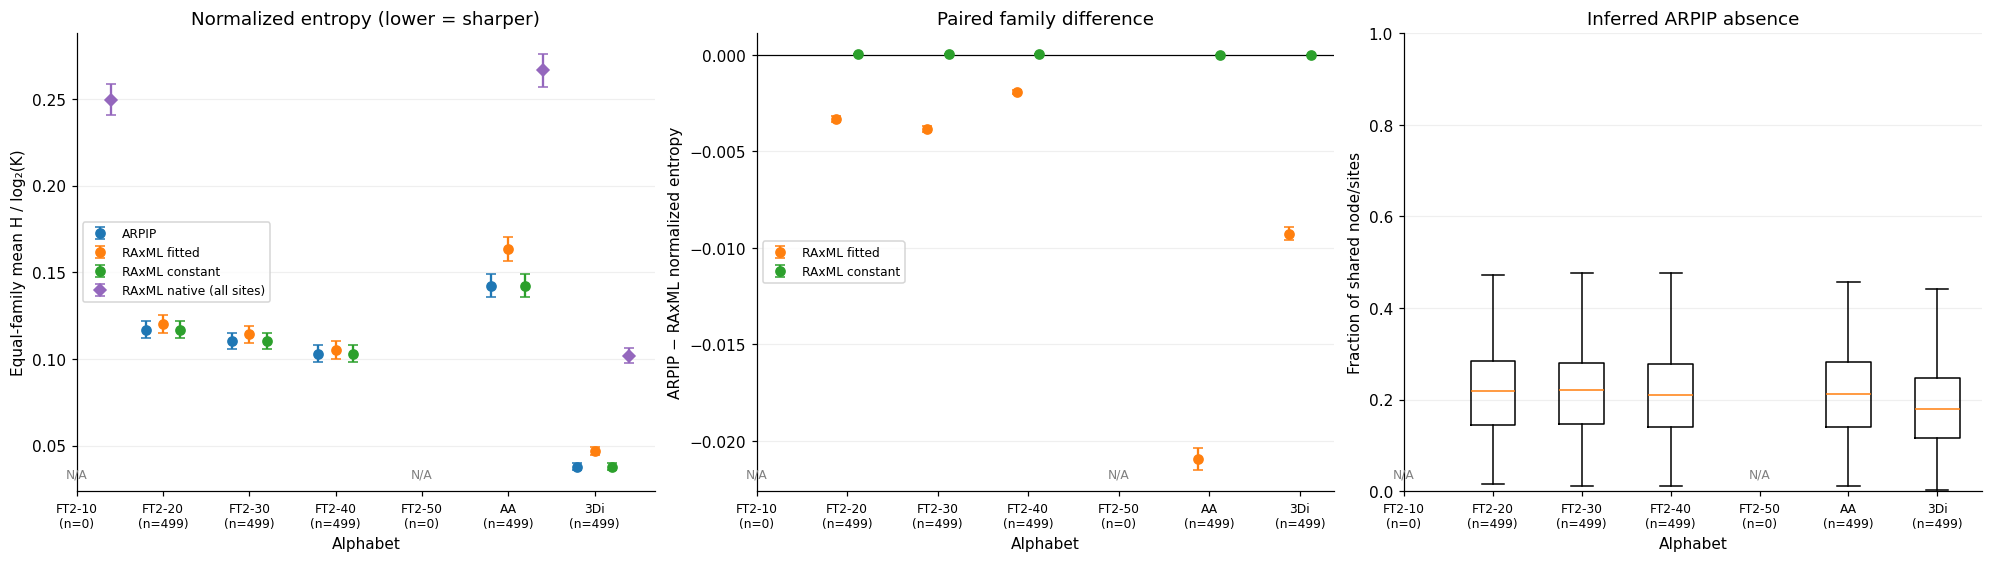

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
plot_representations = ['FT2_10', 'FT2_20', 'FT2_30', 'FT2_40', 'FT2_50', 'AA', '3Di']
x = np.array([plot_representations.index(r) for r in representations])
native_names = ['FT2_10', 'AA', '3Di']
native_x = np.array([plot_representations.index(r) for r in native_names])
colors = {'ARPIP': 'tab:blue', 'RAxML fitted': 'tab:orange', 'RAxML constant': 'tab:green'}
for offset, label in zip((-.2, 0, .2), methods):
    data = indel_intervals[indel_intervals.metric == label].set_index('representation').loc[representations]
    axes[0].errorbar(x + offset, data['mean'],
                     yerr=[data['mean'] - data['lower'], data['upper'] - data['mean']],
                     fmt='o', capsize=3, color=colors[label], label=label)
native_data = indel_intervals[indel_intervals.metric == 'RAxML native'].set_index('representation').loc[native_names]
axes[0].errorbar(native_x + .4, native_data['mean'],
                 yerr=[native_data['mean'] - native_data['lower'], native_data['upper'] - native_data['mean']],
                 fmt='D', capsize=3, color='tab:purple', label='RAxML native (all sites)')
for offset, label in zip((-.12, .12), ('RAxML fitted', 'RAxML constant')):
    data = indel_intervals[indel_intervals.metric == 'ARPIP − ' + label].set_index('representation').loc[representations]
    axes[1].errorbar(x + offset, data['mean'],
                     yerr=[data['mean'] - data['lower'], data['upper'] - data['mean']],
                     fmt='o', capsize=3, color=colors[label], label=label)
axes[1].axhline(0, color='black', linewidth=.8)
gap_values = [paired_indel.loc[paired_indel.representation == representation, 'arpip_gap_fraction'].to_numpy()
              for representation in representations]
axes[2].boxplot(gap_values, positions=x, widths=.5, showfliers=False)
for ax in axes:
    ax.set_xticks(np.arange(len(plot_representations)), labels=[f"{r.replace('_', '-')}\n(n={paired_indel.loc[paired_indel.representation == r, 'family'].nunique()})" for r in plot_representations], fontsize=8)
    for missing in ('FT2_10', 'FT2_50'):
        ax.text(plot_representations.index(missing), .03, 'N/A', transform=ax.get_xaxis_transform(), ha='center', color='gray', fontsize=8)
    ax.set_xlabel('Alphabet')
    ax.grid(axis='y', alpha=.2)
axes[0].set(title='Normalized entropy (lower = sharper)', ylabel='Equal-family mean H / log₂(K)')
axes[1].set(title='Paired family difference', ylabel='ARPIP − RAxML normalized entropy')
axes[2].set(title='Inferred ARPIP absence', ylabel='Fraction of shared node/sites', ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.show()


### How to read these plots

- **Normalized entropy (left):** for a node and alignment position, entropy is $H=-\sum_c p(c)\log_2 p(c)$ across the $K$ possible characters. Dividing by $\log_2 K$ gives 0 for a distribution concentrated on one character and 1 for a uniform distribution. Lower values are sharper. Points first average over eligible node/sites within each family, then weight families equally; bars are 95% family-bootstrap intervals.
- **Paired family difference (middle):** within each family and representation, subtract RAxML normalized entropy from ARPIP normalized entropy on the **same ARPIP-present node/sites**, then average across families. A negative value means ARPIP is sharper; zero means equal entropy. Bars are 95% paired family-bootstrap intervals. The fitted RAxML model may include invariant sites and, for AA and 3Di, gamma rate variation; the constant-rate control removes these components.
- **Inferred ARPIP absence (right):** for each family, the fraction of shared ancestral node/sites reconstructed as a gap by ARPIP. Boxes show the median and interquartile range; whiskers use the standard 1.5-IQR rule and outliers are hidden. These are inferred gap fractions, not probabilities that individual gaps are correct.

ARPIP substitution probabilities condition on its selected insertion point and reconstructed presence mask; they do not integrate over indel histories. Gap sites are excluded from all three paired entropy averages. AA and 3Di now cover all 499 families. FT2-10 and FT2-50 have no paired ARPIP results, so those entries are N/A. The AA, 3Di and FT2-10 diamonds are native **RAxML-only** results over all reconstructed node/sites, using their own alignments and trees; they are descriptive context, not paired comparisons with FT2. Sharper distributions express greater model confidence, **not necessarily greater ancestral accuracy**.